In [1]:
import pandas as pd
from glob import glob
import seaborn as sns
import aquarel
import matplotlib.pyplot as plt

In [2]:
TOPICS = ["301", "304", "306", "307", "311", "318", "319", "321", "324", "343", "352", "353", "354", "357", "360", "367", "370", "374", "383", "389", "390", "391", "392", "395", "398", "399", "400", "404", "408", "412", "415", "418", "422", "424", "425", "431", "434", "435", "436", "438", "439", "443", "450", "631", "656", "683", "688", "700"]

In [3]:
data = []
for f in glob("../data/interim/logs_shallow/*/version_*/metrics.csv"):
    version = f.split("/")[-2].split("_")[-1]
    model, topic = f.split("/")[-3].rsplit("-", 1)
    model_type, model_name = model.split("-", 1)
    model_name, tuning_type = model_name.rsplit("-", 1)
    tmp = (
        pd.read_csv(f)
        .assign(
            model_type=model_type,
            model_name=model_name,
            topic=topic,
            tuning_type=tuning_type,
            version=version,
        )
    )
    try:
        data.append(tmp.loc[:, ["model_type", "model_name", "topic", "tuning_type", "version", "precision", "recall", "accuracy", "f1"]])
    except:
        pass


df_metrics = (
    pd.concat(data)
    .dropna(subset=["precision", "recall", "accuracy", "f1"])
    .assign(
        depth=lambda df: df["version"].replace({
            "0": 64,
            "1": 128,
            "2": 192,
            "3": 256
        })
    )
    .merge(
        (
            pd.read_parquet("../data/interim/run_evals.parquet")
            .loc[:, ["query", "NDCG@10"]]
            .groupby("query")
            .mean()
            .reset_index()
            .rename(columns={"query": "topic", "NDCG@10": "topic_difficulty"})
        ),
        left_on="topic",
        right_on="topic",
        how="left",
    )
    .drop(columns=["version"])
    .dropna(subset=["topic_difficulty"])
)

/var/folders/54/8lplw84d1sbgcm1wmd2rgyd40000gn/T/ipykernel_70569/2493541371.py:27: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  depth=lambda df: df["version"].replace({


In [4]:
df_metrics.loc[:, ["depth", "topic", "precision", "recall", "accuracy", "f1"]]

,depth,topic,precision,recall,accuracy,f1
8,128,324,0.413333,0.855172,0.716138,0.557303
9,64,324,0.242634,0.915033,0.406332,0.383562
10,192,324,0.660714,0.810219,0.868254,0.727869
11,256,324,0.838710,0.806202,0.920495,0.822134
16,128,383,0.172199,0.638462,0.703260,0.271242
...,...,...,...,...,...,...
223,256,392,0.232727,0.876712,0.787234,0.367816
224,128,357,0.282675,0.732283,0.637827,0.407895
225,64,357,0.227652,0.729008,0.537621,0.346957
226,192,357,0.321224,0.682927,0.696566,0.436931


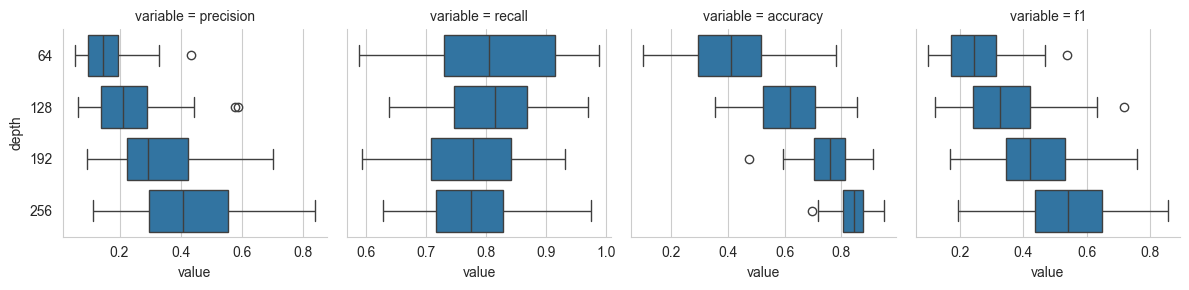

In [5]:
g = sns.FacetGrid(data=(
    df_metrics
    .loc[:, ["depth", "topic", "precision", "recall", "accuracy", "f1"]]
    .astype({"depth": str})
    .melt(id_vars=["depth", "topic"])
), col="variable", aspect=1, height=3, sharex=False, legend_out=True)
g.map(
    sns.boxplot,
    "value",
    "depth",
    order=["64", "128", "192", "256"],
)
plt.show()

In [6]:

for depth in ["64", "128", "192", "256"]:
    qrels = []
    for f in glob(f"../data/interim/output_robust04_shallow_{depth}/*/predictions.json"):
        predictions = pd.read_json(f, lines=True)
        qrels.append(predictions)
    qrels = pd.concat(qrels)
    qrels.to_parquet(f"../data/processed/robust04-shallow-qrels-{depth}.parquet")

In [7]:
import ir_datasets
from tqdm.notebook import tqdm
import trectools

qrels_original = (
    pd.DataFrame(
        ir_datasets
        .load("disks45/nocr/trec-robust-2004")
        .qrels_iter()
    )
    .rename(columns={
        "query_id": "query",
        "doc_id": "docid",
        "relevance": "rel"
    })
    .assign(q0="Q0")
    .drop(columns=["iteration"])
    .query("query in @TOPICS")
)

data = []

for pool_depth in ["64", "128", "192", "256"]:
    qrels_predicted = (
        pd.merge(
            # Index of original
            qrels_original.loc[:, ["query", "docid"]].astype({"query": str, "docid": str}),
            # Values of predicted, where available
            (
                pd.read_parquet(f"../data/processed/robust04-shallow-qrels-{pool_depth}.parquet")
                .rename(columns={
                    "query_id": "query",
                    "doc_id": "docid",
                    "relevance": "rel"
                })
                .assign(q0="Q0")
                .astype({"query": str, "docid": str, "rel": float})
            ),
            on=["query", "docid"],
            how="left",
        )
        # Restrict to test topics
        .query("query in @TOPICS")
        # Fill non-predicted with original
        .fillna(qrels_original)
        # Cast at threshold
        .assign(rel=lambda df: (df["rel"] > 0.5).astype(int))
    )

    def get_ndcg_original():
        qrels = trectools.TrecQrel()
        qrels.qrels_data = qrels_original
        eval_data = []
        for runfile in tqdm(glob("../data/external/robust04-runs/*.gz")):
            run = trectools.TrecRun(runfile)
            run.run_data = run.run_data.query("query in @TOPICS")
            eval = trectools.TrecEval(run, qrels)
            for depth in [5, 10, 50, 1000]:
                eval_data.append(
                    eval.get_ndcg(depth=depth, per_query=True)
                    .reset_index()
                    .assign(system=run.get_runid(), depth=depth)
                    .rename(columns={f"NDCG@{depth}": "ndcg_original"})
                    .query("query in @TOPICS")
                )
        df = pd.concat(eval_data)
        return df

    def get_ndcg_predicted():
        qrels = trectools.TrecQrel()
        qrels.qrels_data = qrels_predicted
        eval_data = []
        for runfile in tqdm(glob("../data/external/robust04-runs/*.gz")):
            run = trectools.TrecRun(runfile)
            eval = trectools.TrecEval(run, qrels)
            for depth in [5, 10, 50, 1000]:
                eval_data.append(
                    eval.get_ndcg(depth=depth, per_query=True)
                    .reset_index()
                    .assign(system=run.get_runid(), depth=depth)
                    .rename(columns={f"NDCG@{depth}": "ndcg_predicted"})
                    .query("query in @TOPICS")
                )
        df = pd.concat(eval_data)
        return df

    data.append(
        pd.concat([
            get_ndcg_original().set_index(["system", "query", "depth"]),
            get_ndcg_predicted().set_index(["system", "query", "depth"])
        ], axis=1)
        .assign(pool_depth=int(pool_depth))
    )

df = pd.concat(data)

  0%|          | 0/110 [00:00<?, ?it/s]

  0%|          | 0/110 [00:00<?, ?it/s]

  0%|          | 0/110 [00:00<?, ?it/s]

  0%|          | 0/110 [00:00<?, ?it/s]

  0%|          | 0/110 [00:00<?, ?it/s]

  0%|          | 0/110 [00:00<?, ?it/s]

  0%|          | 0/110 [00:00<?, ?it/s]

  0%|          | 0/110 [00:00<?, ?it/s]

In [8]:
df.columns = ['ndcg_original', 'ndcg_predicted', 'pool_depth']

In [9]:
df.to_parquet("../data/processed/robust04-eval_scores.parquet")

In [10]:
df_corr = (
    df
    .reset_index()
    .drop(columns="query")
    .groupby(["system", "depth", "pool_depth"])
    .mean()
    .reset_index()
    .set_index("system")
    .groupby(["depth", "pool_depth"])
    .corr(method="spearman")
    .reset_index()
    .query("level_2 == 'ndcg_original'")
    .drop(columns=["level_2", "ndcg_original"])
    .rename(columns={"pool_depth": "Training Samples"})
    .pivot(index="Training Samples", columns="depth", values="ndcg_predicted")
    .round(3)
    .reset_index()
    .rename(columns={k: f"p(nDCG@{k})" for k in [5, 10, 50, 1000]})
)

In [11]:
df_corr.melt(id_vars=["Training Samples"])

,Training Samples,depth,value
0,64,p(nDCG@5),0.396
1,128,p(nDCG@5),0.652
2,192,p(nDCG@5),0.764
3,256,p(nDCG@5),0.789
4,64,p(nDCG@10),0.633
5,128,p(nDCG@10),0.792
6,192,p(nDCG@10),0.885
7,256,p(nDCG@10),0.896
8,64,p(nDCG@50),0.810
9,128,p(nDCG@50),0.887


<Axes: xlabel='depth', ylabel='Spearman Rank Correlation'>

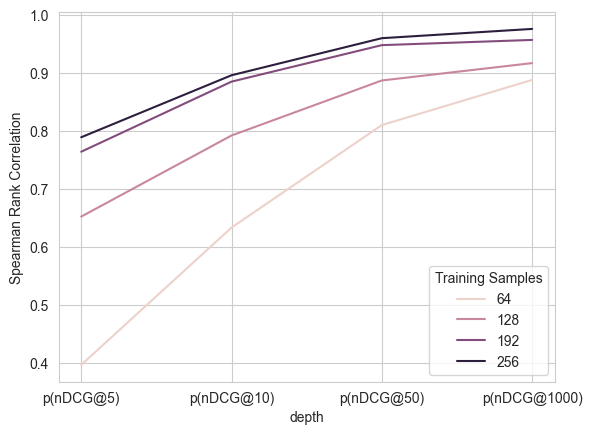

In [12]:
import seaborn as sns

sns.lineplot(
    data=df_corr.melt(id_vars=["Training Samples"]).rename(columns={"value": "Spearman Rank Correlation"}),
    hue="Training Samples",
    y="Spearman Rank Correlation",
    x="depth",
)


In [13]:
df_ranks = (
    df
    .reset_index()
    .dropna()
    .drop(columns="query")
    .groupby(["system", "depth", "pool_depth"])
    .mean()
    .reset_index()
    .assign(
        rank_original=lambda df: (
            df
            .sort_values("ndcg_original", ascending=False)
            .groupby(["depth", "pool_depth"])
            .cumcount() + 1
        ),
        rank_predicted=lambda df: (
            df
            .sort_values("ndcg_predicted", ascending=False)
            .groupby(["depth", "pool_depth"])
            .cumcount() + 1
        )
    )
    .drop(columns=["ndcg_original", "ndcg_predicted"])
)
df_ranks

,system,depth,pool_depth,rank_original,rank_predicted
0,JuruDes,5,64,82,74
1,JuruDes,5,128,84,87
2,JuruDes,5,192,82,59
3,JuruDes,5,256,85,64
4,JuruDes,10,64,67,79
...,...,...,...,...,...
1755,wdoqsn1,50,256,72,73
1756,wdoqsn1,1000,64,85,86
1757,wdoqsn1,1000,128,85,86
1758,wdoqsn1,1000,192,85,87


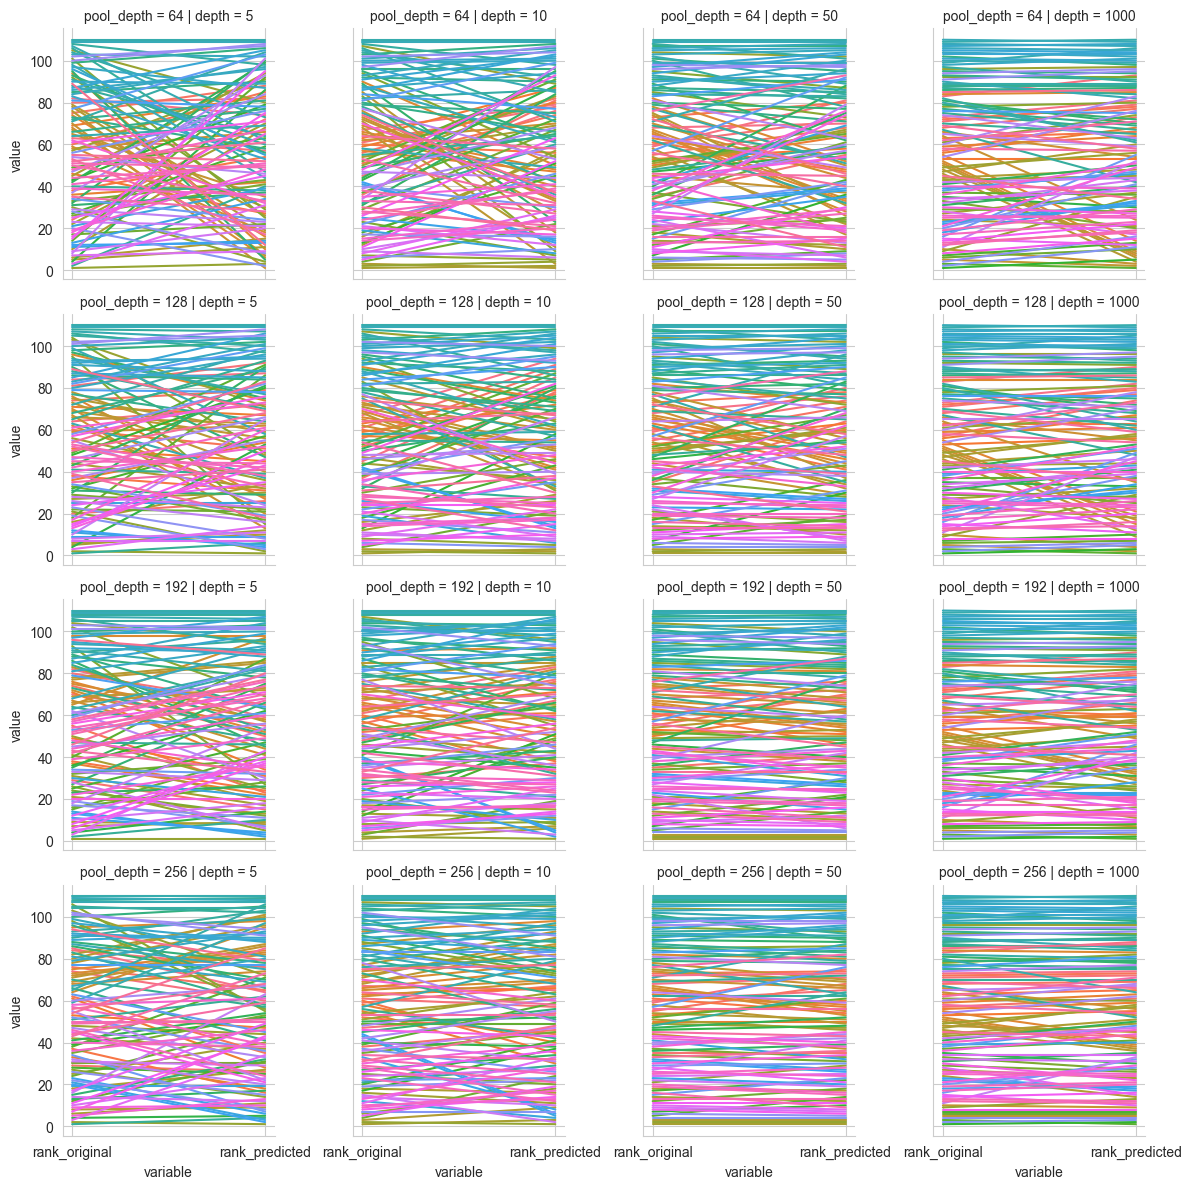

In [14]:
g = sns.FacetGrid(
    data=df_ranks.melt(id_vars=["system", "depth", "pool_depth"]),
    col="depth",
    row="pool_depth",
)
g.map(sns.lineplot,
    "variable",
    "value",
    "system",
    legend=False
)

In [15]:
df_ranks["diff"] = (df_ranks["rank_original"] - df_ranks["rank_predicted"]).apply(abs)

In [16]:
(
    df_ranks
    .assign(bin=lambda df: pd.cut(df["rank_original"], bins=10, labels=False))
    .drop(columns=["system", "rank_original", "rank_predicted"])
    .groupby(["depth", "pool_depth", "bin"])
    .mean()
    .reset_index()
    .query("depth == 10")
    .pivot(index=["pool_depth"], columns="bin", values="diff")
    #.loc[:, ["depth", "pool_depth", "bin", "diff"]]
    .round(2)
)

bin,0,1,2,3,4,5,6,7,8,9
pool_depth,,,,,,,,,,
64,11.82,19.27,20.73,31.09,23.36,15.27,38.55,25.00,21.82,9.82
128,5.27,14.91,10.73,22.18,20.09,15.18,24.45,17.00,12.45,5.91
192,7.00,10.64,10.36,15.64,13.45,16.09,12.82,12.73,10.00,4.00
256,8.55,9.09,10.45,14.82,8.18,11.00,11.36,12.82,9.73,2.91


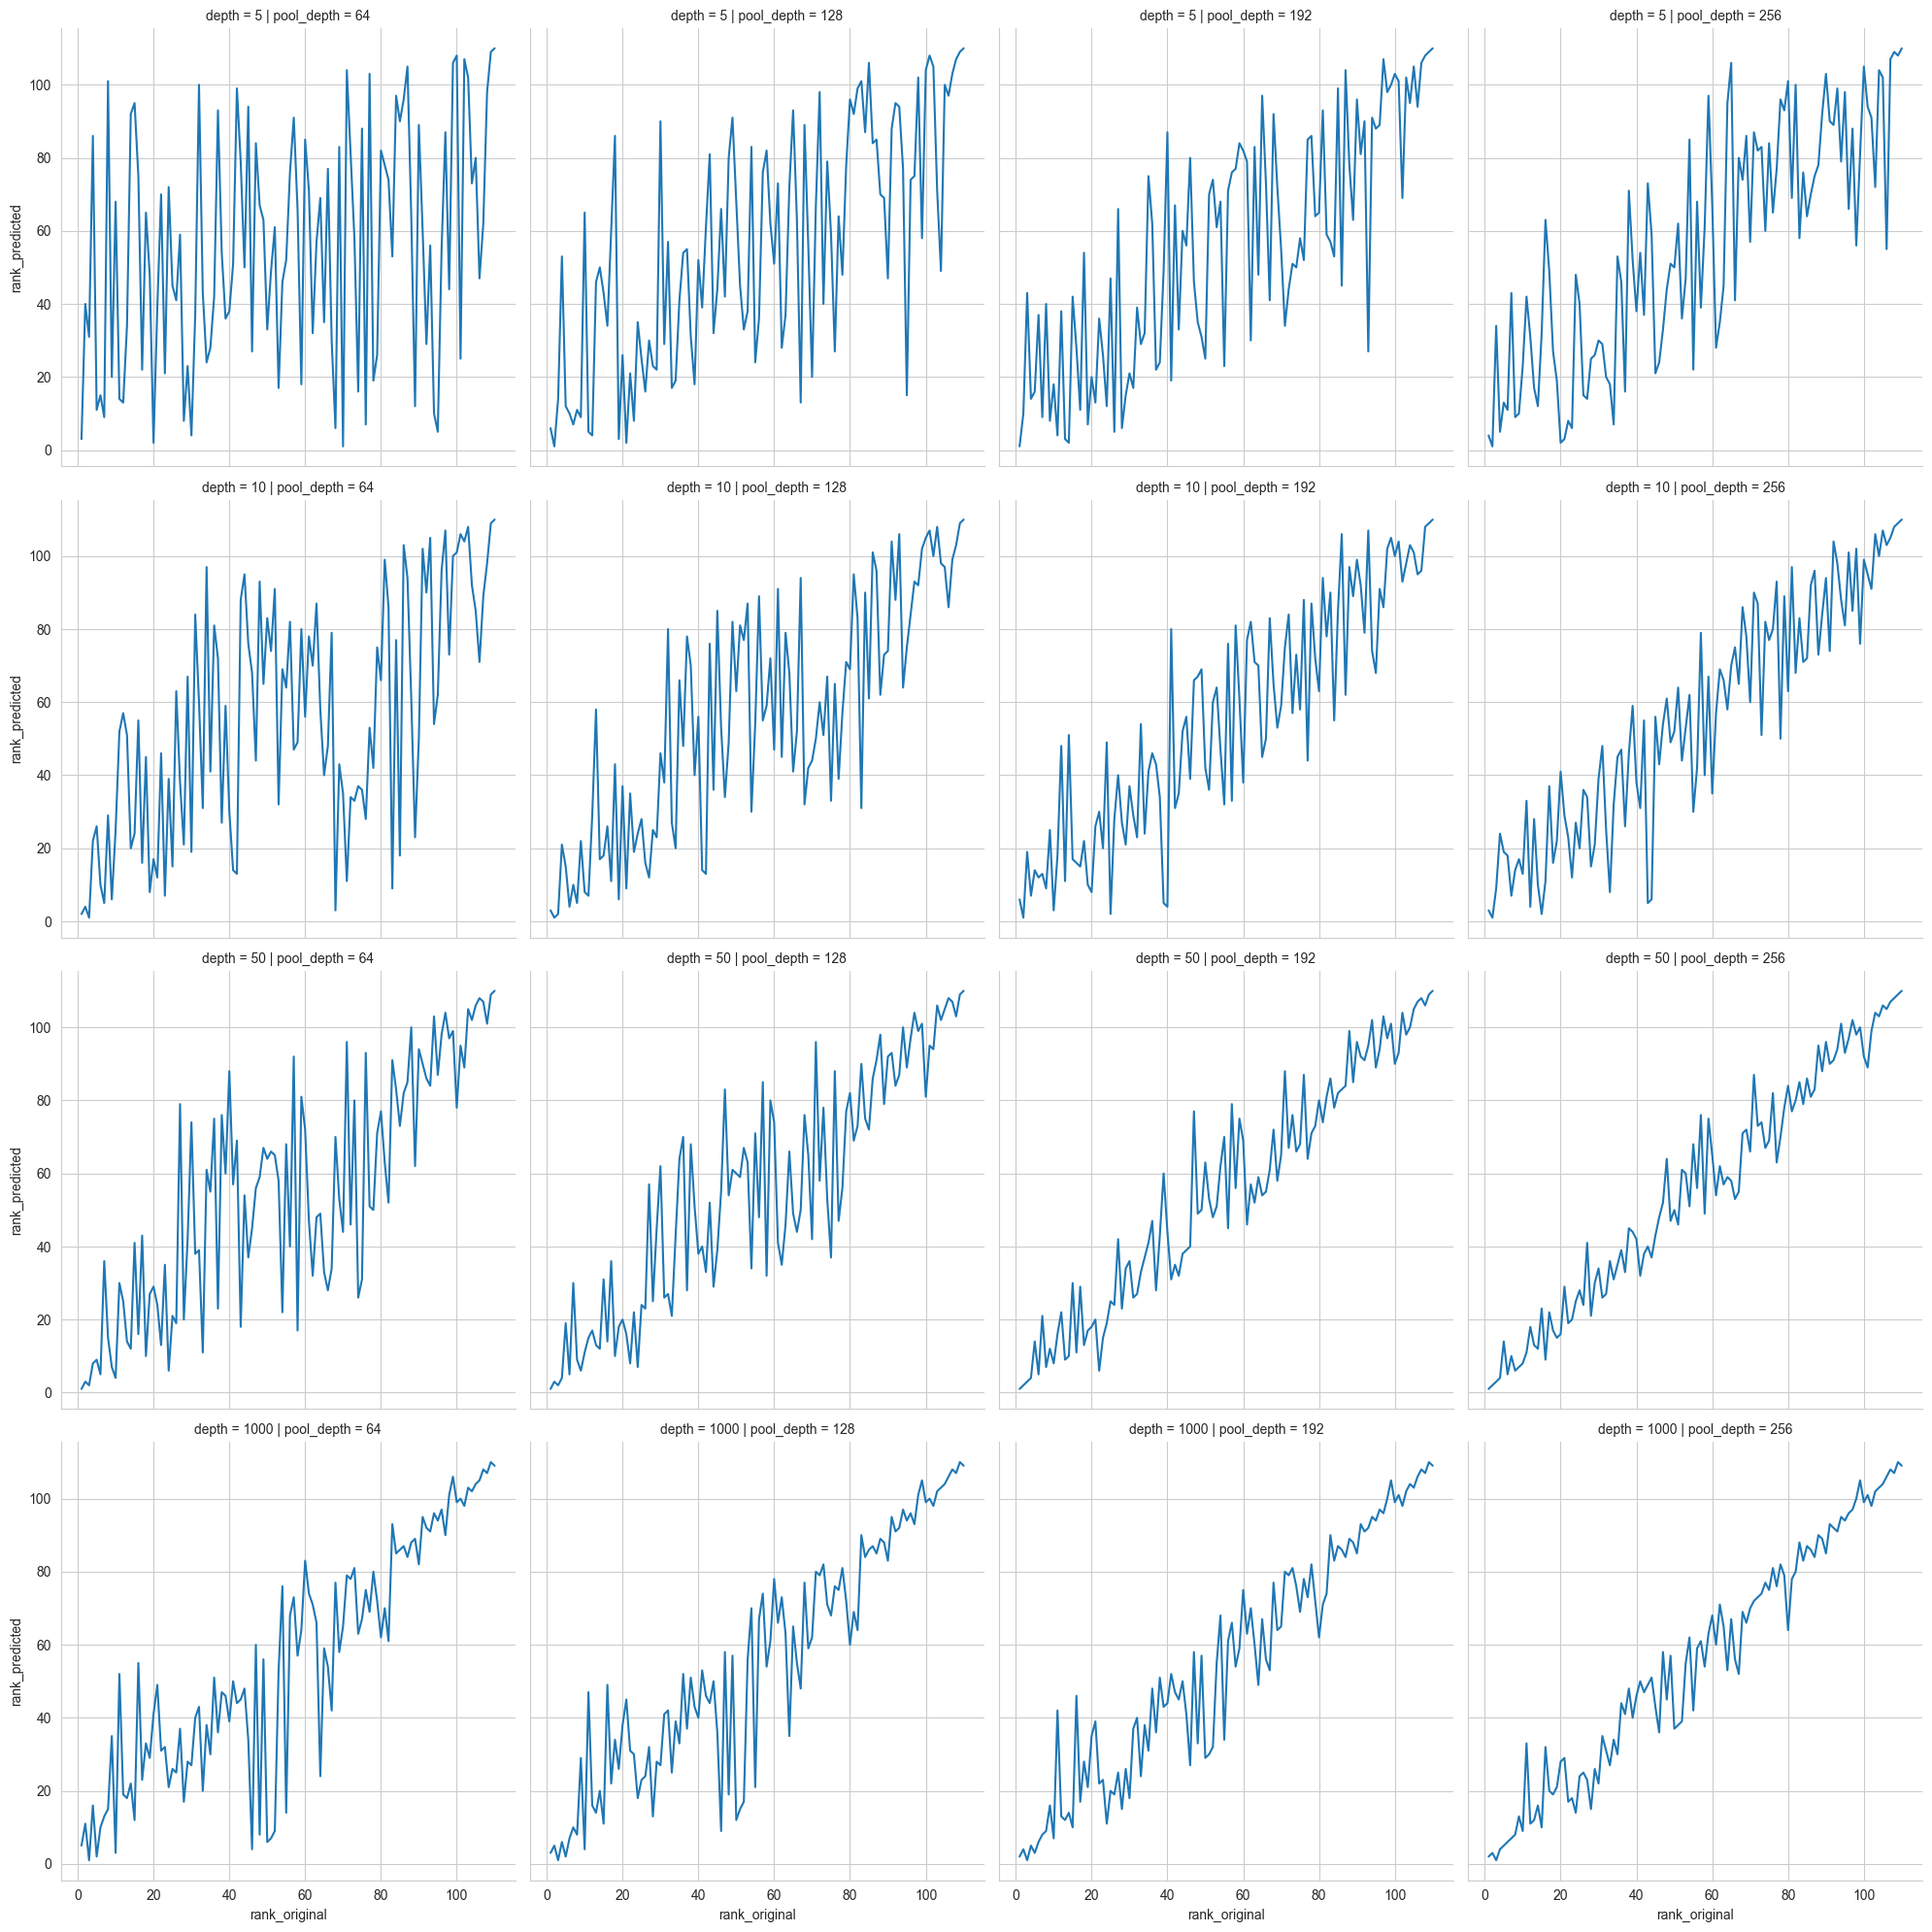

In [17]:
g = sns.relplot(
    data=df_ranks.astype({"pool_depth": str, "depth": str}),
    col="pool_depth",
    row="depth",
    kind="line",
    x="rank_original",
    y="rank_predicted",
)

for ax in g.axes.flatten():
    ax.invert_yaxis()
    ax.invert_xaxis()